

---



---


# Multi-class Semantic Segmentation on the PanNuke Histological Dataset
---



---



## % Libraries - Imports

In [1]:
import os
import random
import sys

import numpy as np
import torch
from torch.utils.data import DataLoader, Subset

import matplotlib
import matplotlib.pyplot as plt
import torchvision

In [2]:
# double-check the installed versions of the key libraries
print(f"numpy version:        {np.__version__}")
print(f"torch version:         {torch.__version__}")
print(f"torchvision version:   {torchvision.__version__}")
print(f"matplotlib version:    {matplotlib.__version__}")


numpy version:        2.1.3
torch version:         2.11.0+cu130
torchvision version:   0.26.0+cu130
matplotlib version:    3.10.0


## % Mount Google drive

In [3]:
# mount Google Drive when running on Colab, otherwise use the local project folder
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = ""
except ImportError:
    PROJECT_DIR = os.getcwd()   # running locally, from the project folder

print("PROJECT_DIR:", PROJECT_DIR)

Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/Colab Notebooks/Deep_learning_course/Final_project/PanNuke


In [4]:
# import the functions/classes that were moved into .py files
# (the .py files are next to data_root/ in the project folder)
sys.path.insert(0, PROJECT_DIR)

from pannuke_dataset import *
from pannuke_utils import *
from model_unet_plusplus import UNetPlusPlus

### --- Load data - PanNuke dataset - Fold1 ---
PanNuke Dataset for Nuclei Instance Segmentation and Classification - https://huggingface.co/datasets/RationAI/PanNuke

In [5]:
# load the PanNuke Fold1 images and their per-category instance masks
images = np.load(PROJECT_DIR + "/data_root/images.npy")
masks = np.load(PROJECT_DIR + "/data_root/masks.npy")

# sanity-check the loaded array shapes and dtypes
print("images shape:", images.shape, "images dtype:", images.dtype)
print("masks shape:", masks.shape, "masks dtype:", masks.dtype)

images shape: (2656, 256, 256, 3) images dtype: float64
masks shape: (2656, 256, 256, 6) masks dtype: float64


# Architecture improvement - Unet++

## % CONFIGURATION + Parameters setting + Data preparation for model training

In [6]:
# --- CONFIGURATION ---
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 16
LEARNING_RATE = 0.0001
NUM_EPOCHS = 160
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15
CHECKPOINT_DIR = PROJECT_DIR + '/data_root/checkpoints_UNet++_full'

# fix all RNG seeds so the run is reproducible
SEED = 54
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.backends.cudnn.deterministic = True

# make sure the checkpoint folder exists
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

In [7]:
# rebuild the dataset for the UNet++ run (augmentation enabled)
# two views of the same data: augmented for training, clean for validation/test
train_full_dataset = PanNukeDataset(images, masks, augment=True)
eval_full_dataset  = PanNukeDataset(images, masks, augment=False)

Dataset ready: 2656 samples
Dataset ready: 2656 samples


### --- Training/Validation/Test data creation ---

In [8]:
# re-split into train/val/test (fresh shuffle, same ratios as before)
n = len(train_full_dataset)
indices = list(range(n))
# shuffle before splitting so train/val/test are randomly sampled
random.shuffle(indices)

# compute split sizes from the configured ratios
n_val = int(n * VAL_SPLIT)
n_test = int(n * TEST_SPLIT)

# slice the shuffled indices into val / test / train
val_idx = indices[:n_val]
test_idx = indices[n_val:n_val + n_test]
train_idx = indices[n_val + n_test:]

print(f"Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}")

Train: 1860 | Val: 398 | Test: 398


In [9]:
# wrap each split's indices into a Subset, then into a DataLoader for batching
# only the training split reads from the augmented dataset
train_dataset = Subset(train_full_dataset, train_idx)
val_dataset = Subset(eval_full_dataset, val_idx)
test_dataset = Subset(eval_full_dataset, test_idx)

# only shuffle the training loader; keep val/test order fixed
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

### --- Model + optimizer - UNet++ ---

In [10]:
# create the UNet++ model and optimizer
model_UNetPlusPlus = UNetPlusPlus(num_classes=6).to(DEVICE)

optimizer_UNetPlusPlus = torch.optim.Adam(model_UNetPlusPlus.parameters(), lr=LEARNING_RATE)

### --- Train UNet++ ---

In [ ]:
# training loop for UNet++
print("Starting Training...")

# track loss/Dice history and keep the best checkpoint by validation Dice
history = {"train_loss": [], "train_dice": [], "val_loss": [], "val_dice": []}
best_val_dice = 0.0

for epoch in range(NUM_EPOCHS):
    # 1. Train
    train_loss, train_dice = train_model(model = model_UNetPlusPlus,
                             training_data = train_loader,
                             num_classes=6,
                             optimizer = optimizer_UNetPlusPlus)

    # 2. Validate
    val_loss, val_dice = validate_model(model = model_UNetPlusPlus,
                                        validation_data = val_loader,
                                        num_classes=6)

    # 3. Store for plotting later
    history["train_loss"].append(train_loss)
    history["train_dice"].append(train_dice)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)

    # 4. Print Stats
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
          f"||| Train Loss: {train_loss:.4f} | Train Dice: {train_dice:.4f} "
          f"||| Val Loss: {val_loss:.4f} | Val Dice: {val_dice:.4f}")

    # checkpoint whenever validation Dice improves
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        checkpoint_path = os.path.join(CHECKPOINT_DIR, f'UNetPlusPlus_best_result_{epoch}.pth')
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model_UNetPlusPlus.state_dict(),
            'optimizer_state_dict': optimizer_UNetPlusPlus.state_dict(),
            'val_dice': val_dice
        }, checkpoint_path)
        print(f"   >>> Improvement! Saving model (Dice: {val_dice:.4f})")

print(f"\nTraining Complete. Best Validation Dice: {best_val_dice:.4f}")

Starting Training...
Epoch [1/160] ||| Train Loss: 0.8509 | Train Dice: 0.2008 ||| Val Loss: 0.8189 | Val Dice: 0.2674
   >>> Improvement! Saving model (Dice: 0.2674)
Epoch [2/160] ||| Train Loss: 0.8068 | Train Dice: 0.2907 ||| Val Loss: 0.7820 | Val Dice: 0.3288
   >>> Improvement! Saving model (Dice: 0.3288)
Epoch [3/160] ||| Train Loss: 0.7760 | Train Dice: 0.3384 ||| Val Loss: 0.7637 | Val Dice: 0.3575
   >>> Improvement! Saving model (Dice: 0.3575)
Epoch [4/160] ||| Train Loss: 0.7527 | Train Dice: 0.3574 ||| Val Loss: 0.7315 | Val Dice: 0.3716
   >>> Improvement! Saving model (Dice: 0.3716)
Epoch [5/160] ||| Train Loss: 0.7298 | Train Dice: 0.3738 ||| Val Loss: 0.7130 | Val Dice: 0.3788
   >>> Improvement! Saving model (Dice: 0.3788)
Epoch [6/160] ||| Train Loss: 0.7089 | Train Dice: 0.3889 ||| Val Loss: 0.6993 | Val Dice: 0.3947
   >>> Improvement! Saving model (Dice: 0.3947)
Epoch [7/160] ||| Train Loss: 0.6898 | Train Dice: 0.3980 ||| Val Loss: 0.6664 | Val Dice: 0.4101
   >>

### --- Plot the progress ---

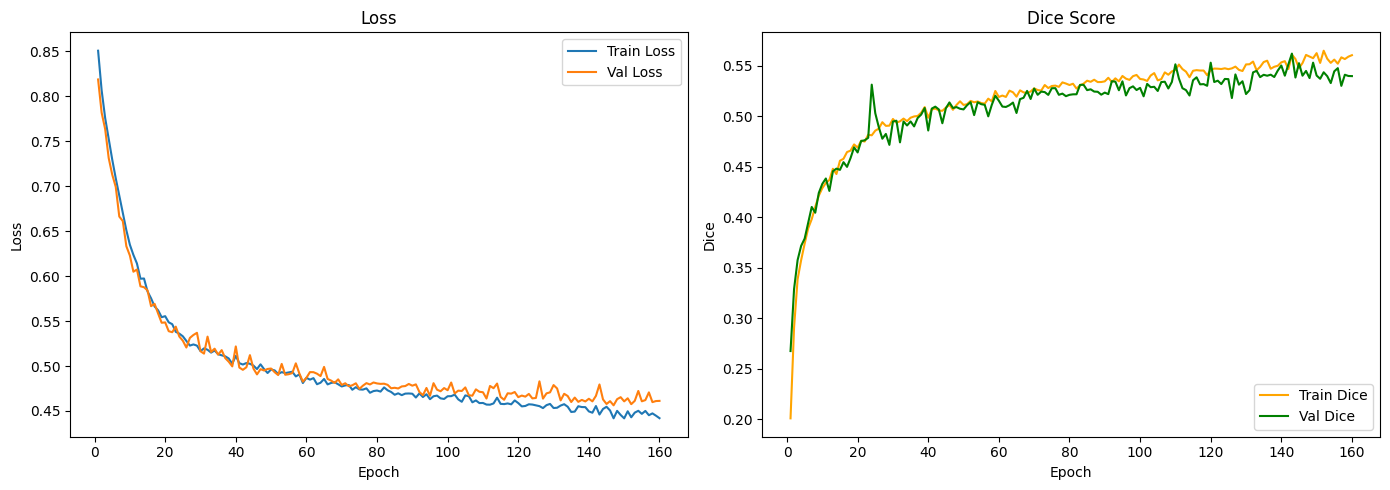

In [ ]:
# plot loss/Dice curves for this run
epochs = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
ax1.plot(epochs, history["train_loss"], label="Train Loss")
ax1.plot(epochs, history["val_loss"], label="Val Loss")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()

# Dice plot
ax2.plot(epochs, history["train_dice"], label="Train Dice", color="orange")
ax2.plot(epochs, history["val_dice"], label="Val Dice", color="green")
ax2.set_title("Dice Score")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice")
ax2.legend()

plt.tight_layout()
plt.show()

### --- Conclusion ---

After finishing the training of the UNetPlusPLus model we can see the following:

**Loss graph:**
*   Train and Val Loss both decrease smoothly
*   Around epoch 150-160 the gap between the 2 losses starts to increase slowly



---
**Dice graph:**
*   Train Dice increases nicely
*   After epoch 50 the improvement slows down significantly
*   Around epoch 150-160 the gap between the 2 dicess starts to increase slowly


---

With the above configuration, the UNet++ model could reach its best at **Epoch [143/160]**, where the results were the following:
*   Train Loss: 0.4460 | Train Dice: 0.5610 ||| Val Loss: 0.4795 | Val Dice: 0.5620


---
**At Epoch 143:**
*   => model generalizes well
*   => no overfitting at this epoch
*   => this Val Dice is a peak above the usual 0.54 - 0.55 range of the last epochs, the learning slows down but does not entirely stop, however a slight sign of overfitting is there (the Train-Val gap slowly grows towards the end)


*Comparing SimpleUNet2 with Unet++, the following are the differences:

1.   Deeper architecture: SimpleUNet2: 3
encoder + 3 decoder blocks
UNet++: 4 encoder blocks + multiple refinement columns
     *   SimpleUNet2: 3
          encoder + 3 decoder blocks
     *   UNet++: 4 encoder blocks + multiple  refinement columns
2.   Intermediate nodes:
     *   SimpleUNet2: encoder connects directly to decoder (one jump)
     *   UNet++: encoder connects through intermediate nodes that gradually refine the features
3. More Dropout:
     *   SimpleUNet2: dropout only in decoder
     *   UNet++: dropout in all intermediate nodes     



*Comparing SimpleUNet2 with UNet++, the more complex architecture brought an improvement — Val Dice increased from 0.5262 to 0.5620. However, SimpleUNet2 was trained only for 120 epochs (UNet++ for 160) and its learning had slowed down but not stopped, so we can not be entirely sure that further training would not have brought it closer to, or even above, the UNet++ result.
The learning rate was decreased from 0.0005 to 0.0001 and the batch-size was also decreased from 64 to 16. The dense skip connections and intermediate refinement nodes allowed the model to learn more detailed features, assuming in better segmentation performance. However, a slight sign of overfitting appears towards the end of the training: the Train-Val Dice gap slowly grows from about 0.01 (epochs 80 - 125) to about 0.02 (epochs 148 - 160), while the Val Dice has not started to decrease. This suggests that further regularization or a pretrained encoder could push the results even higher.*


### --- UNet++ predictions ---

In [11]:
# reload the best UNet++ checkpoint
checkpoint = torch.load(
    PROJECT_DIR + "/data_root/checkpoints_UNet++_full/UNetPlusPlus_best_result_142.pth",
    map_location=DEVICE,
    weights_only=False
)
model_UNetPlusPlus = UNetPlusPlus(num_classes=6).to(DEVICE)
model_UNetPlusPlus.load_state_dict(checkpoint["model_state_dict"])

print(f"Model loaded from epoch {checkpoint['epoch']}")
print(f"Best Val Dice: {checkpoint['val_dice']:.4f}")

Model loaded from epoch 143
Best Val Dice: 0.5620


### --- Test set evaluation ---

In [12]:
# quantitative evaluation on the held-out test set
test_loss, test_dice = validate_model(model=model_UNetPlusPlus, validation_data=test_loader, num_classes=6)
print(f"Test Loss: {test_loss:.4f} | Test Dice: {test_dice:.4f}")

Test Loss: 0.4690 | Test Dice: 0.5751


In [13]:
# visualize predictions from the UNet++ model
visualize_predictions(model_UNetPlusPlus, test_dataset, num_images=6)

Output hidden; open in https://colab.research.google.com to view.